In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

files = sorted(Path(".").glob("results_*.csv"))
print("found:", [f.name for f in files])

results = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
results = results.sort_values("f1", ascending=False).reset_index(drop=True)
results

found: ['results_01.csv', 'results_02.csv', 'results_03.csv']


,model,accuracy,precision,recall,f1
0,NB + Bag-of-Words,0.826,0.819,0.790,0.801
1,LR + TF-IDF (balanced),0.811,0.793,0.811,0.799
2,LR + TF-IDF,0.803,0.798,0.756,0.769
3,LR + GloVe,0.780,0.764,0.739,0.747
4,Word list + negation,0.760,0.774,0.681,0.693
5,LR + Word2Vec,0.736,0.714,0.677,0.685
6,Word list,0.729,0.721,0.649,0.656
7,NB + TF-IDF,0.742,0.828,0.636,0.633


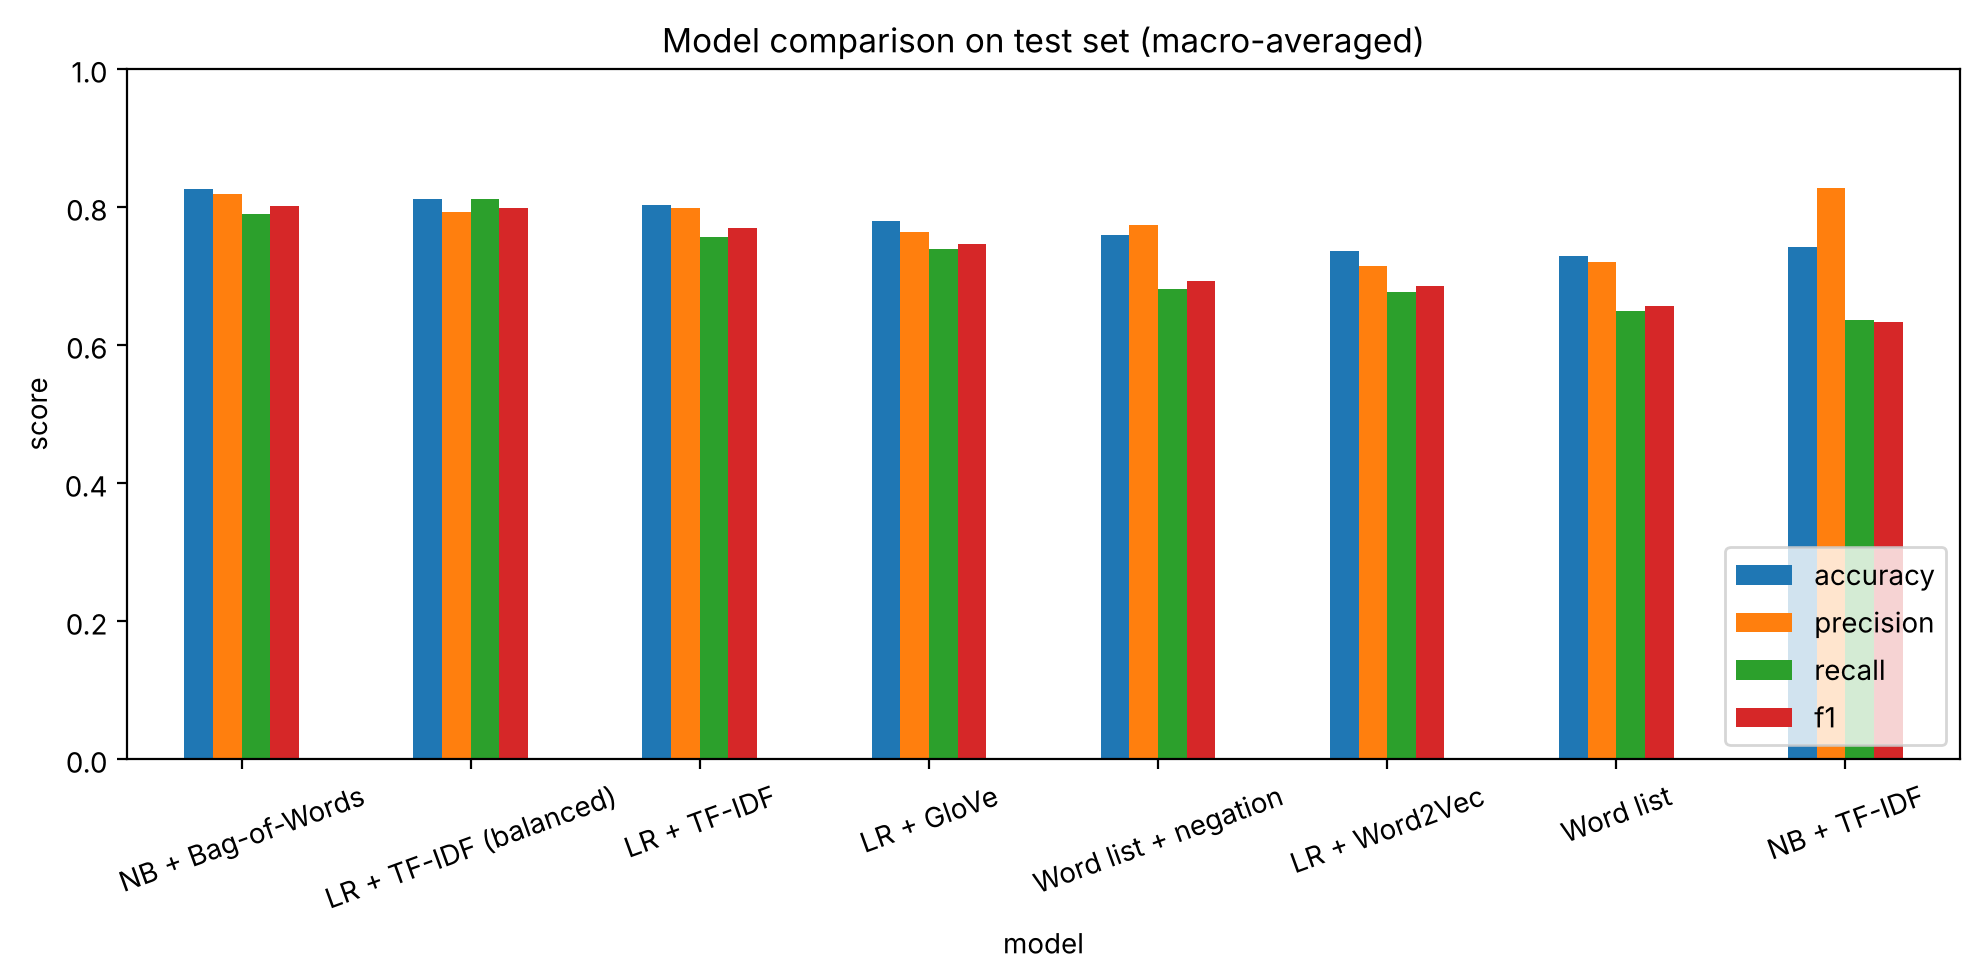

In [2]:
ax = results.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=20
)
ax.set_ylabel("score")
ax.set_title("Model comparison on test set (macro-averaged)")
ax.legend(loc="lower right")
plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/fig4_model_comparison.png", dpi=150)
plt.show()